<div align="center">

# Assignment 10 — Hierarchical Agglomerative Clustering

---

**Name:** Shreyas Sovani &nbsp;|&nbsp; **Roll No:** 22 &nbsp;|&nbsp; **Class:** AIML-F &nbsp;|&nbsp; **Subject:** Machine Learning

---

</div>


# Assignment 10 — Hierarchical Agglomerative Clustering

*Unsupervised Learning: Bottom-Up Tree Construction, Linkage Criteria, Dendrogram Cutting, and Cophenetic Validation*

**Datasets:** A hand-made 8-point toy set, synthetic shapes (moons, circles, blobs of different spread), and Wine (178 wines, 13 features, 3 cultivars) — built into scikit-learn.

**Objective:** Build the cluster tree bottom-up from scratch and verify it against SciPy, compare linkage criteria, cut dendrograms into flat clusters, and validate trees with the cophenetic correlation coefficient.

## 1. Theory

Agglomerative (bottom-up) clustering builds a **tree of nested clusters**:

1. Start with every point as its own cluster ($n$ clusters)
2. Find the two **closest** clusters and **merge** them
3. Update the distances from the new cluster to all the others
4. Repeat until one cluster remains — exactly $n - 1$ merges

The merge history is drawn as a **dendrogram**: leaves are the points, and the height of each join is the distance at which the two clusters merged. Unlike K-Means, no $K$ is needed up front.

**Linkage criteria** — how the distance between clusters $A$ and $B$ is measured:

- **Single:** $d(A, B) = \min_{a \in A,\, b \in B} d(a, b)$ — follows chains and finds non-convex shapes, but is sensitive to noise
- **Complete:** $d(A, B) = \max_{a \in A,\, b \in B} d(a, b)$ — compact clusters of similar diameter
- **Average:** $d(A, B) = \frac{1}{\lvert A \rvert \lvert B \rvert} \sum_{a \in A} \sum_{b \in B} d(a, b)$ — a compromise between single and complete
- **Ward:** merge the pair that least increases the within-cluster sum of squares, $\Delta(A, B) = \frac{\lvert A \rvert \lvert B \rvert}{\lvert A \rvert + \lvert B \rvert} \lVert \boldsymbol{\mu}_A - \boldsymbol{\mu}_B \rVert^2$ — spherical, similar-size clusters (like K-Means)

**Dendrogram cutting** — a horizontal cut at height $h$ turns the tree into flat clusters: every subtree hanging below the cut is one cluster. Cutting where the vertical gap between successive merges is largest gives the most "natural" number of clusters.

**Cophenetic validation** — the *cophenetic distance* $c(i, j)$ is the height at which points $i$ and $j$ first end up in the same cluster. The **cophenetic correlation coefficient** is the Pearson correlation between the original distances $d(i, j)$ and $c(i, j)$ over all pairs:

$$r_c = \frac{\sum_{i<j} (d_{ij} - \bar{d})(c_{ij} - \bar{c})}{\sqrt{\sum_{i<j} (d_{ij} - \bar{d})^2 \, \sum_{i<j} (c_{ij} - \bar{c})^2}}$$

$r_c$ close to 1 means the tree preserves the original pairwise distances faithfully.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster, cophenet
from scipy.spatial.distance import pdist, squareform
from sklearn.datasets import load_wine, make_moons, make_circles, make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score

sns.set_theme(style='whitegrid')
%matplotlib inline

---
# Part A — Building the Tree from Scratch (Toy Data)

Eight labelled points: two tight groups (A–C and D–F), a "bridge" point G between them, and an outlier H.

In [2]:
pts = np.array([[1.0, 1.0], [1.6, 1.3], [1.2, 2.1],
                [5.0, 5.2], [5.8, 4.6], [6.1, 5.9],
                [3.4, 3.1], [8.6, 1.2]])
names = list('ABCDEFGH')

D = pd.DataFrame(squareform(pdist(pts)), index=names, columns=names)
D.round(2)

,A,B,C,D,E,F,G,H
A,0.00,0.67,1.12,5.80,6.00,7.07,3.19,7.60
B,0.67,0.00,0.89,5.17,5.34,6.44,2.55,7.00
C,1.12,0.89,0.00,4.90,5.24,6.20,2.42,7.45
D,5.80,5.17,4.90,0.00,1.00,1.30,2.64,5.38
E,6.00,5.34,5.24,1.00,0.00,1.33,2.83,4.40
F,7.07,6.44,6.20,1.30,1.33,0.00,3.89,5.32
G,3.19,2.55,2.42,2.64,2.83,3.89,0.00,5.54
H,7.60,7.00,7.45,5.38,4.40,5.32,5.54,0.00


In [3]:
LINKAGES = {'single': np.min, 'complete': np.max, 'average': np.mean}


def agglomerative(X, method='single'):
    """Naive bottom-up clustering; returns a SciPy-style linkage matrix."""
    n = len(X)
    dist = squareform(pdist(X))
    clusters = {i: [i] for i in range(n)}      # cluster id -> member points
    Z, next_id = [], n
    while len(clusters) > 1:
        ids = list(clusters)
        best = (np.inf, None, None)
        for a in range(len(ids)):
            for b in range(a + 1, len(ids)):
                block = dist[np.ix_(clusters[ids[a]], clusters[ids[b]])]
                d = LINKAGES[method](block)
                if d < best[0]:
                    best = (d, ids[a], ids[b])
        d, i, j = best
        clusters[next_id] = clusters.pop(i) + clusters.pop(j)
        Z.append([i, j, d, len(clusters[next_id])])
        next_id += 1
    return np.array(Z)


def print_merges(Z, names):
    label = list(names)
    for step, (i, j, d, size) in enumerate(Z, 1):
        a, b = label[int(i)], label[int(j)]
        label.append(''.join(sorted(a + b)))
        print(f'Step {step}: {a:>7} + {b:<7} -> {label[-1]:<8} '
              f'at height {d:.3f}')

In [4]:
for method in ['single', 'complete']:
    print(f'--- {method} linkage ---')
    print_merges(agglomerative(pts, method), names)
    print()

--- single linkage ---
Step 1:       A + B       -> AB       at height 0.671
Step 2:       C + AB      -> ABC      at height 0.894
Step 3:       D + E       -> DE       at height 1.000
Step 4:       F + DE      -> DEF      at height 1.304
Step 5:       G + ABC     -> ABCG     at height 2.417
Step 6:     DEF + ABCG    -> ABCDEFG  at height 2.640
Step 7:       H + ABCDEFG -> ABCDEFGH at height 4.405

--- complete linkage ---
Step 1:       A + B       -> AB       at height 0.671
Step 2:       D + E       -> DE       at height 1.000
Step 3:       C + AB      -> ABC      at height 1.118
Step 4:       F + DE      -> DEF      at height 1.334
Step 5:       G + ABC     -> ABCG     at height 3.189
Step 6:       H + DEF     -> DEFH     at height 5.381
Step 7:    ABCG + DEFH    -> ABCDEFGH at height 7.603



Same data, different stories. **Single** linkage lets the bridge point G pull A–C and D–F together early (chaining), and H is left until last. **Complete** linkage judges clusters by their farthest members, so G joins A–C much later and H is absorbed into D–F before the final merge.

## Verification against SciPy

In [5]:
for method in LINKAGES:
    ours = agglomerative(pts, method)
    ref = linkage(pts, method=method)
    print(f'{method:<8} linkage matrix identical to SciPy: '
          f'{np.allclose(ours, ref)}')

single   linkage matrix identical to SciPy: True
complete linkage matrix identical to SciPy: True
average  linkage matrix identical to SciPy: True


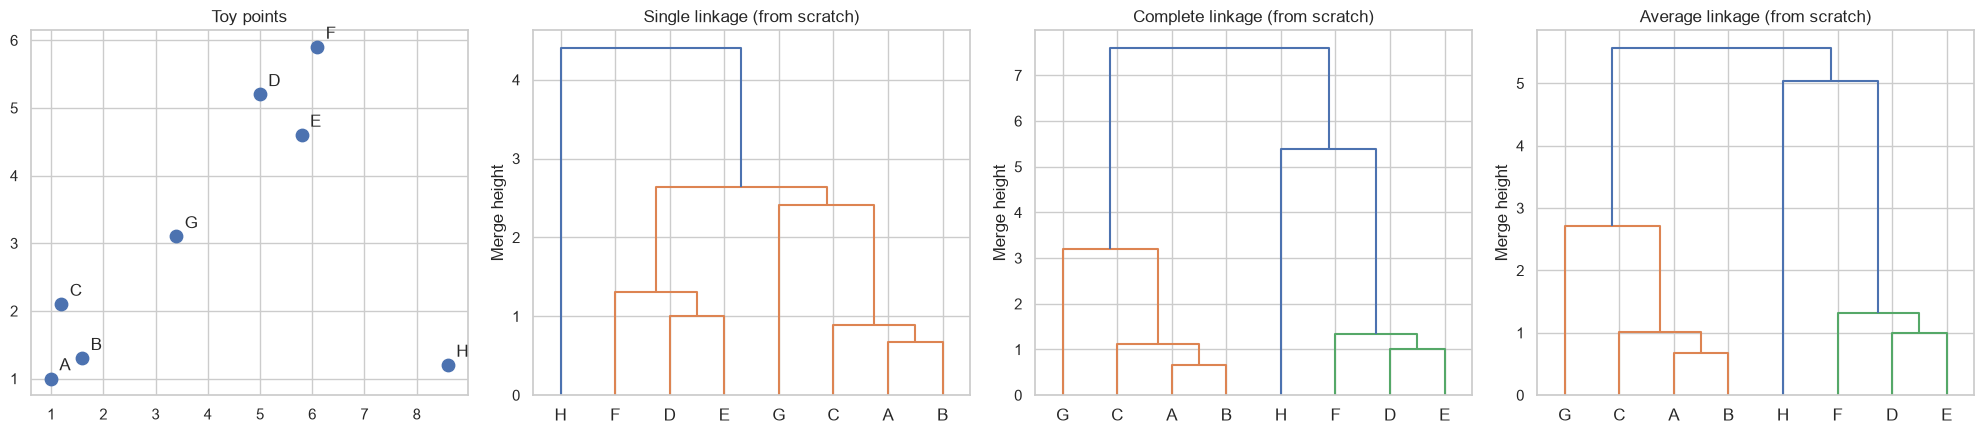

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
axes[0].scatter(pts[:, 0], pts[:, 1], s=80)
for (x, y), name in zip(pts, names):
    axes[0].annotate(name, (x, y), xytext=(6, 6), textcoords='offset points',
                     fontsize=12)
axes[0].set_title('Toy points')
for ax, method in zip(axes[1:], LINKAGES):
    dendrogram(agglomerative(pts, method), labels=names, ax=ax)
    ax.set_title(f'{method.capitalize()} linkage (from scratch)')
    ax.set_ylabel('Merge height')
plt.tight_layout()
plt.show()

---
# Part B — Comparing Linkage Criteria (Synthetic Shapes)

Each dataset is clustered into its true number of groups with every linkage; the title shows the Adjusted Rand Index (ARI: 1 = perfect match with the true groups, 0 = random).

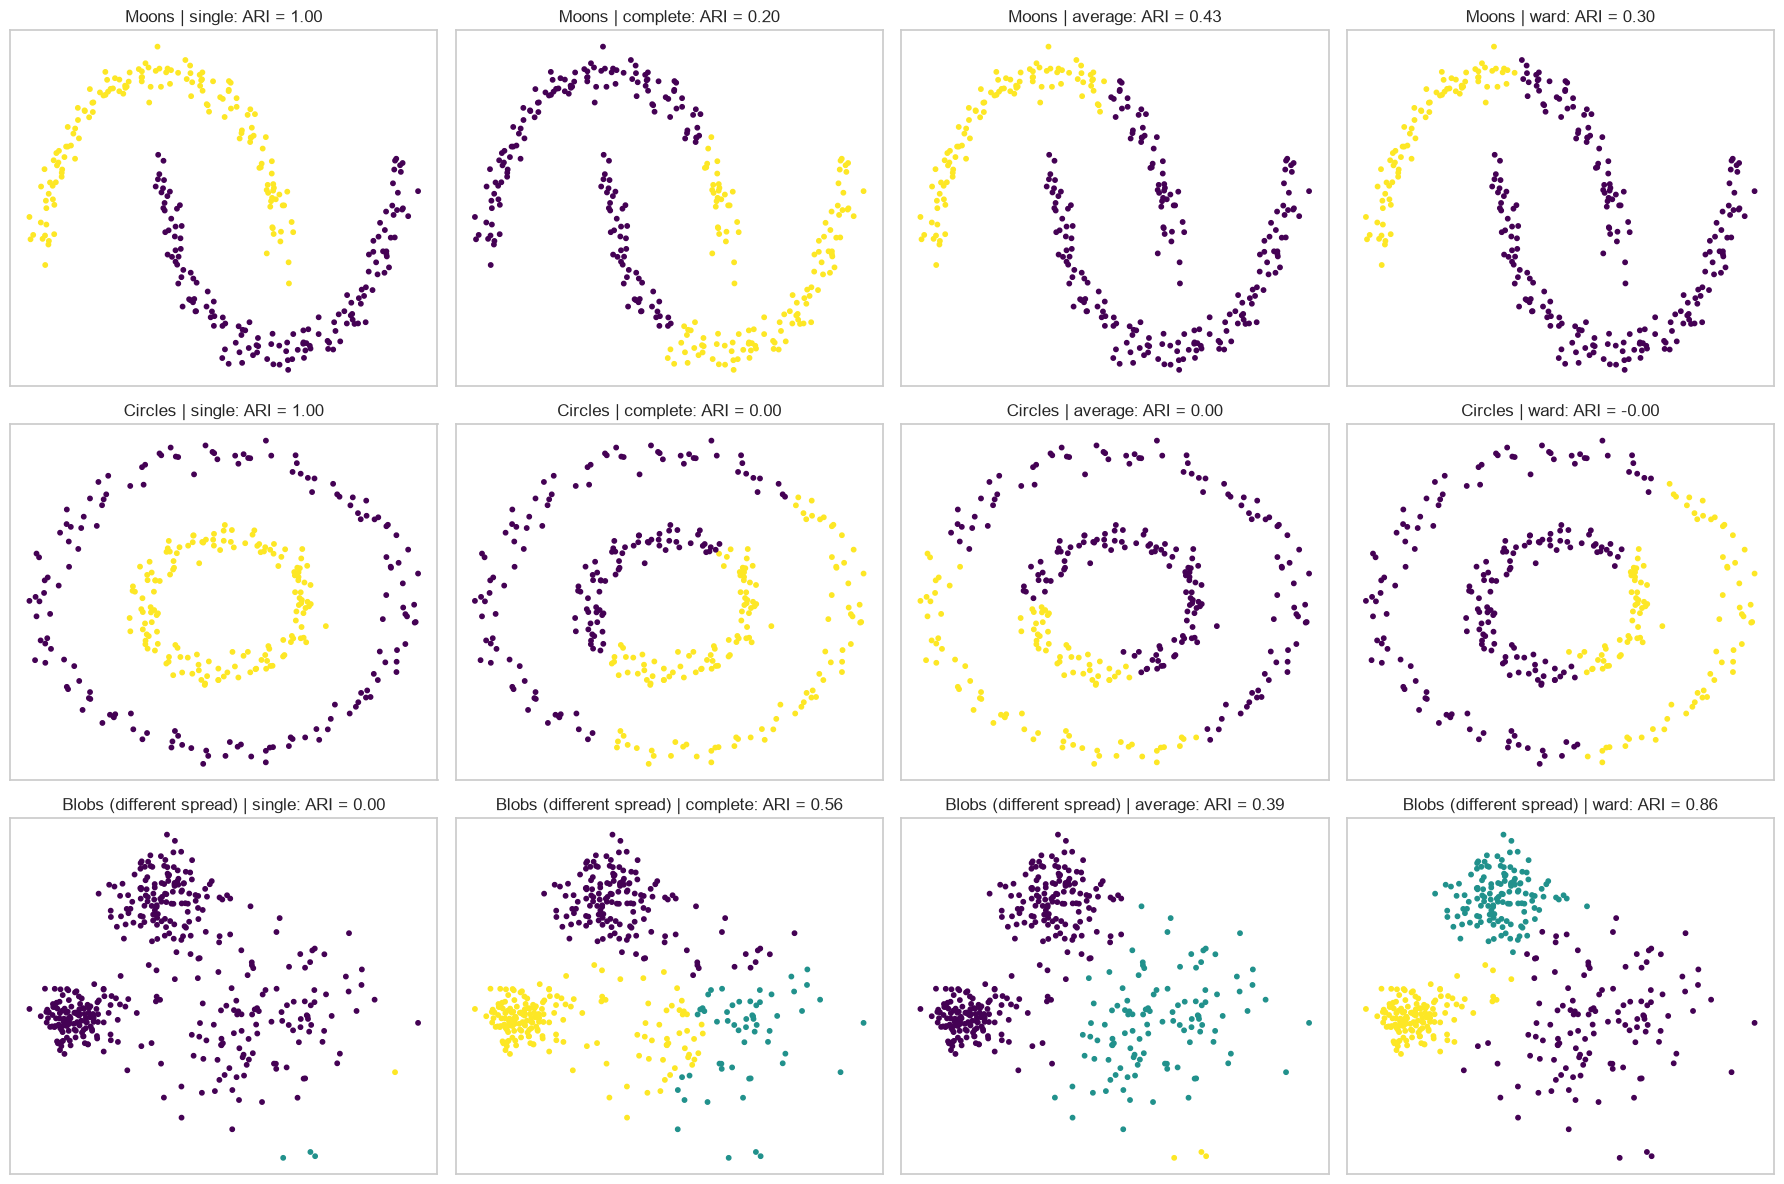

In [7]:
Xm, ym = make_moons(n_samples=300, noise=0.06, random_state=0)
Xc, yc = make_circles(n_samples=300, factor=0.45, noise=0.05, random_state=0)
Xb, yb = make_blobs(n_samples=400, centers=[[0, 0], [5, 0], [2.5, 4]],
                    cluster_std=[0.5, 1.6, 0.8], random_state=0)
shapes = {'Moons': (Xm, ym, 2), 'Circles': (Xc, yc, 2),
          'Blobs (different spread)': (Xb, yb, 3)}
methods = ['single', 'complete', 'average', 'ward']

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
for row, (name, (Xs, ys, k)) in enumerate(shapes.items()):
    for col, method in enumerate(methods):
        lab = AgglomerativeClustering(n_clusters=k, linkage=method) \
            .fit_predict(Xs)
        ax = axes[row, col]
        ax.scatter(Xs[:, 0], Xs[:, 1], c=lab, cmap='viridis', s=10)
        ax.set_title(f'{name} | {method}: '
                     f'ARI = {adjusted_rand_score(ys, lab):.2f}')
        ax.set_xticks([])
        ax.set_yticks([])
plt.tight_layout()
plt.show()

- **Single linkage** is the only criterion that recovers the moons and the circles perfectly — it just follows chains of nearby points. On the blobs it fails completely: the wide blob "leaks" into its neighbours, and one cluster swallows almost everything.
- **Ward** (and to a lesser extent complete) wins on the blobs, but splits the non-convex shapes straight down the middle, because it prefers compact, roughly spherical clusters.
- There is no universally best linkage — the choice encodes an assumption about cluster shape.

---
# Part C — Real Data: Dendrograms, Cutting & Cophenetic Validation (Wine)

The 13 Wine features have very different scales, so they are standardised first (as in Assignment 8).

In [8]:
wine = load_wine()
Xw = StandardScaler().fit_transform(wine.data)
yw = wine.target
print('Shape:', Xw.shape)

dists = pdist(Xw)
links = {m: linkage(Xw, method=m) for m in methods}

Shape: (178, 13)


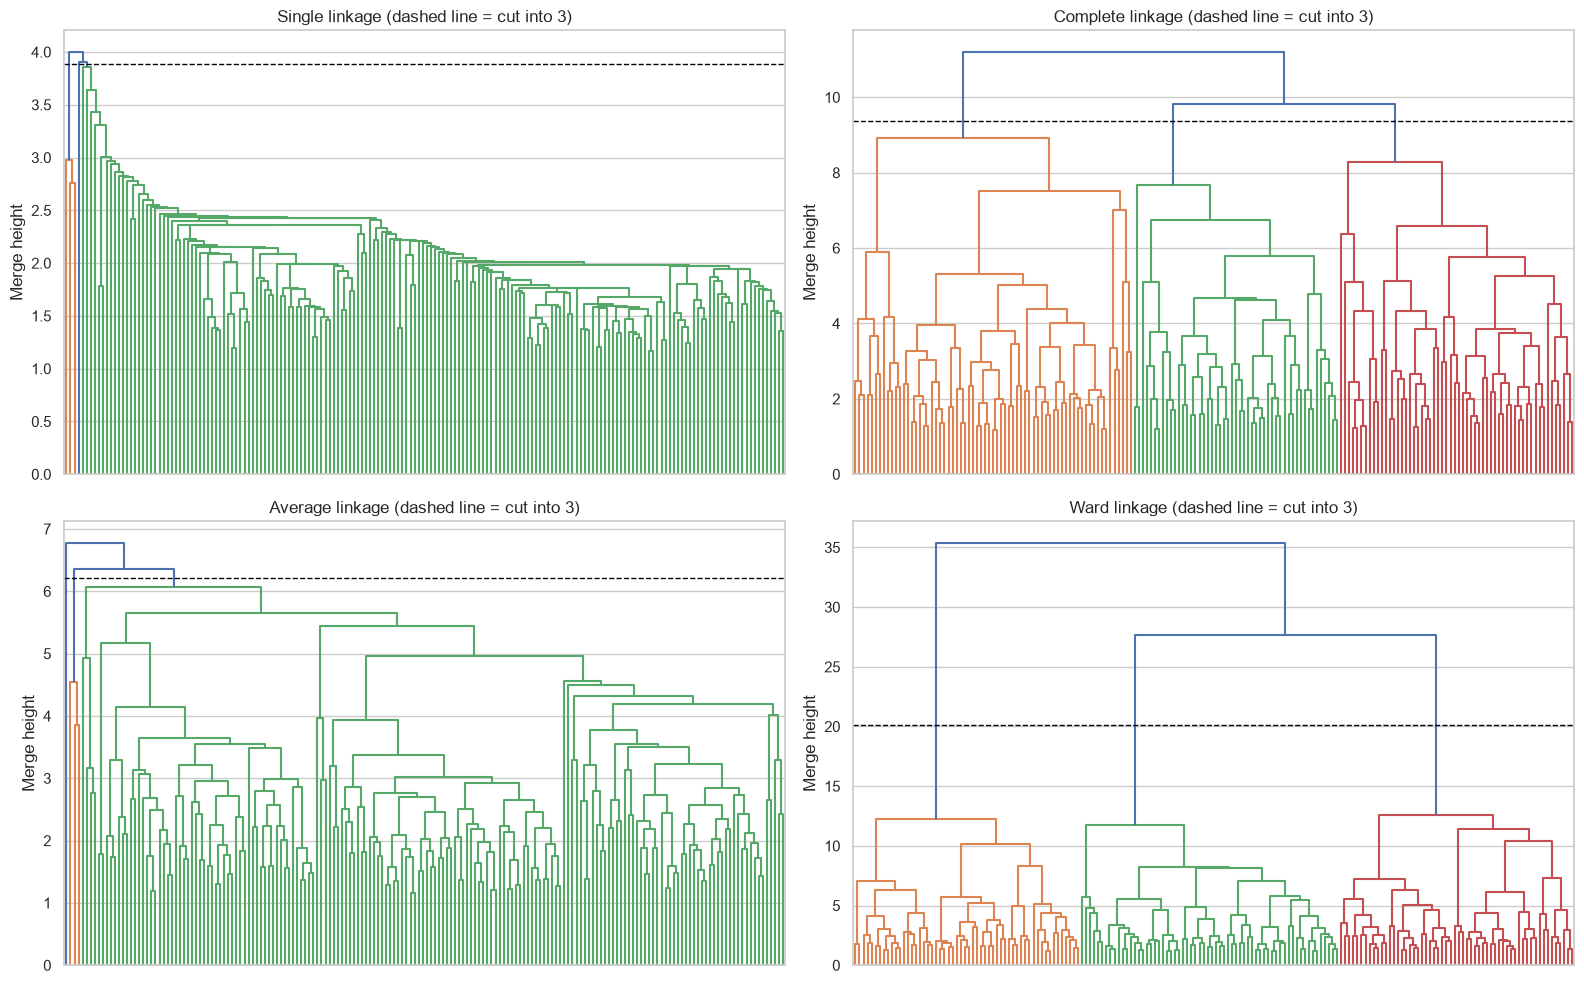

In [9]:
def cut_height(Z, k):
    """Height halfway between the merges that leave k and k-1 clusters."""
    return (Z[-k, 2] + Z[-(k - 1), 2]) / 2


fig, axes = plt.subplots(2, 2, figsize=(16, 10))
for ax, (method, Z) in zip(axes.ravel(), links.items()):
    h = cut_height(Z, 3)
    dendrogram(Z, no_labels=True, color_threshold=h, ax=ax)
    ax.axhline(h, ls='--', color='black', lw=1)
    ax.set_title(f'{method.capitalize()} linkage (dashed line = cut into 3)')
    ax.set_ylabel('Merge height')
plt.tight_layout()
plt.show()

The tree shapes differ dramatically. Single and average linkage produce long "staircase" trees where points join one at a time, so a 3-cluster cut gives one giant cluster plus a couple of stragglers. Complete and especially Ward give balanced trees with clearly separated branches.

## Cophenetic Validation

In [10]:
rows = []
for method, Z in links.items():
    r_c, _ = cophenet(Z, dists)
    lab = fcluster(Z, t=3, criterion='maxclust')
    rows.append({'Linkage': method,
                 'Cophenetic corr': r_c,
                 'Cluster sizes (K=3)': sorted(np.bincount(lab)[1:],
                                               reverse=True),
                 'ARI vs cultivar': adjusted_rand_score(yw, lab),
                 'Silhouette': silhouette_score(Xw, lab)})
summary = pd.DataFrame(rows).set_index('Linkage')
summary.round(3)

,Cophenetic corr,Cluster sizes (K=3),ARI vs cultivar,Silhouette
Linkage,,,,
single,0.544,"[174, 3, 1]",-0.007,0.183
complete,0.592,"[69, 58, 51]",0.577,0.204
average,0.759,"[174, 3, 1]",-0.005,0.158
ward,0.662,"[64, 58, 56]",0.790,0.277


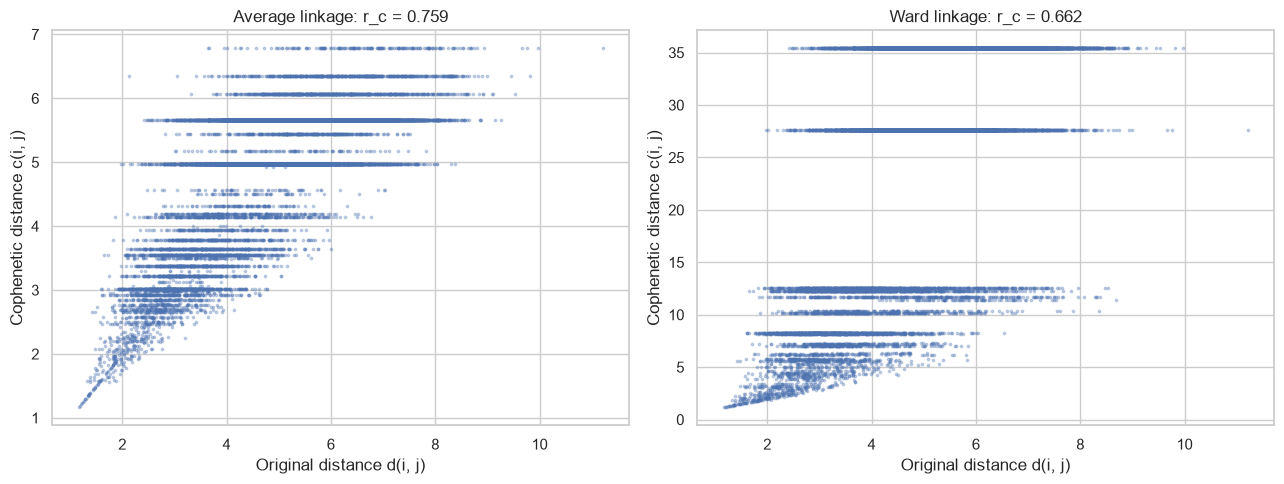

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, method in zip(axes, ['average', 'ward']):
    r_c, coph = cophenet(links[method], dists)
    ax.scatter(dists, coph, s=3, alpha=0.3)
    ax.set_xlabel('Original distance d(i, j)')
    ax.set_ylabel('Cophenetic distance c(i, j)')
    ax.set_title(f'{method.capitalize()} linkage: r_c = {r_c:.3f}')
plt.tight_layout()
plt.show()

**Average** linkage has the highest cophenetic correlation — its merge heights track the original distances most faithfully — yet its 3-cluster cut is useless (ARI $\approx$ 0). **Ward** distorts distances more (merge heights measure the increase in SSE, which grows quickly for large clusters) but gives by far the best clusters. The cophenetic coefficient validates how well the *tree* represents the data, not how good a particular *cut* is, so it should be read alongside cluster-quality measures.

## Cutting the Ward Dendrogram

In [12]:
Z = links['ward']
heights = Z[:, 2]
gaps = np.diff(heights)
g = int(np.argmax(gaps))                 # largest jump between merges
h_cut = (heights[g] + heights[g + 1]) / 2
k_auto = len(heights) - g

print('Last 6 merge heights:', np.round(heights[-6:], 2))
print(f'Largest gap: {heights[g]:.2f} -> {heights[g + 1]:.2f}, '
      f'cut at h = {h_cut:.2f} -> {k_auto} clusters')

lab_dist = fcluster(Z, t=h_cut, criterion='distance')
lab_k = fcluster(Z, t=3, criterion='maxclust')
print('Cut by distance == cut by maxclust=3:',
      adjusted_rand_score(lab_dist, lab_k) == 1.0)

Last 6 merge heights: [11.38 11.72 12.23 12.57 27.65 35.4 ]
Largest gap: 12.57 -> 27.65, cut at h = 20.11 -> 3 clusters
Cut by distance == cut by maxclust=3: True


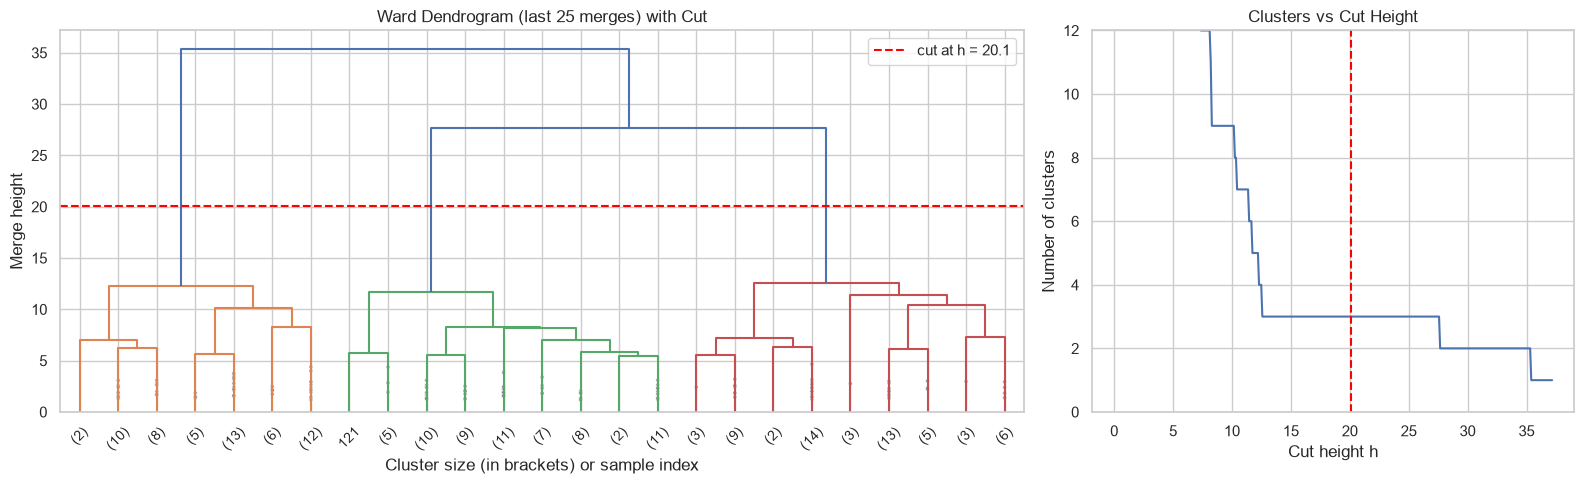

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5),
                         gridspec_kw={'width_ratios': [2, 1]})
dendrogram(Z, truncate_mode='lastp', p=25, color_threshold=h_cut,
           show_contracted=True, ax=axes[0])
axes[0].axhline(h_cut, ls='--', color='red', label=f'cut at h = {h_cut:.1f}')
axes[0].set_title('Ward Dendrogram (last 25 merges) with Cut')
axes[0].set_xlabel('Cluster size (in brackets) or sample index')
axes[0].set_ylabel('Merge height')
axes[0].legend()

hs = np.linspace(0, heights.max() * 1.05, 400)
n_clusters = [len(np.unique(fcluster(Z, t=h, criterion='distance')))
              for h in hs]
axes[1].plot(hs, n_clusters)
axes[1].axvline(h_cut, ls='--', color='red')
axes[1].set_ylim(0, 12)
axes[1].set_xlabel('Cut height h')
axes[1].set_ylabel('Number of clusters')
axes[1].set_title('Clusters vs Cut Height')
plt.tight_layout()
plt.show()

The 3-cluster solution survives the widest range of cut heights (the long flat step), which is why the largest-gap rule picks it.

## Ward Clusters vs the True Cultivars

In [14]:
print(f'ARI vs cultivar: {adjusted_rand_score(yw, lab_k):.3f}\n')
pd.crosstab(pd.Categorical.from_codes(yw, wine.target_names), lab_k,
            rownames=['Cultivar'], colnames=['Cluster'])

ARI vs cultivar: 0.790



Cluster,1,2,3
Cultivar,,,
class_0,0,59,0
class_1,8,5,58
class_2,48,0,0


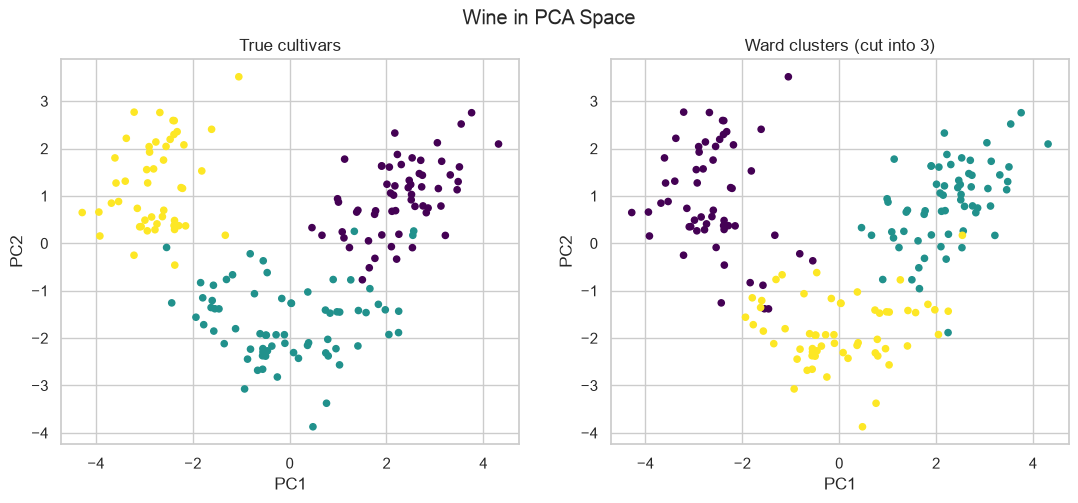

In [15]:
P = PCA(n_components=2).fit_transform(Xw)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(P[:, 0], P[:, 1], c=yw, cmap='viridis', s=20)
axes[0].set_title('True cultivars')
axes[1].scatter(P[:, 0], P[:, 1], c=lab_k, cmap='viridis', s=20)
axes[1].set_title('Ward clusters (cut into 3)')
for ax in axes:
    ax.set_xlabel('PC1')
    ax.set_ylabel('PC2')
plt.suptitle('Wine in PCA Space')
plt.show()

## Conclusion

- **Bottom-up construction:** the from-scratch algorithm reproduces SciPy's linkage matrix exactly for single, complete and average linkage, and the merge logs show how the linkage choice changes the tree (single linkage chains through the bridge point G).
- **Linkage criteria:** single linkage is the only one that separates moons and circles (ARI = 1.0) but collapses on blobs of different spread; Ward is best on compact blobs (ARI $\approx$ 0.86) and on the real Wine data.
- **Dendrogram cutting:** the largest gap between Ward merge heights (12.6 to 27.7) gives **3 clusters** — the true number of cultivars — and cutting by height or by `maxclust=3` gives identical labels.
- **Cophenetic validation:** average linkage preserves the original distances best ($r_c \approx$ 0.76) but its 3-cluster cut is a single giant cluster (ARI $\approx$ 0); Ward has a lower $r_c$ ($\approx$ 0.66) but recovers the cultivars with **ARI $\approx$ 0.79**. A faithful tree is not the same as useful clusters.
- Hierarchical clustering needs no $K$ up front and shows structure at every scale, but costs $O(n^2)$ memory for the distance matrix and merges can never be undone.